# Del silbido al piano

Examen práctico grupal de IA (Algoritmos Genéticos). Un silbido se convierte en una melodía tocada por un piano
sintético cuyos 12 parámetros evoluciona un algoritmo genético implementado desde cero.

El notebook sigue este orden:

1. Notas del silbido, 2. cromosoma, 3. síntesis del instrumento y 4. fitness (la base del AG).
5. Operadores genéticos: selección, cruce y mutación.
6. Ciclo del AG y comparación de tres combinaciones de operadores (C1, C2 y C3).
7. Configuraciones: 12 variaciones de un parámetro a la vez, con 3 semillas cada una.
8. Meta-evaluación: 10 corridas de la configuración base, comparación con una búsqueda aleatoria, sensibilidad de
   los genes (tornado), prueba con una nota no vista (G4) y audios finales.

Las corridas largas guardan sus resultados en `resultados/*.csv` y el notebook los lee si existen. Los interruptores
`RECALCULAR`, `CORRER_CONFIGS`, `CORRER_META` y `CORRER_AZAR` valen `False`; con ese valor el notebook completo
tarda unos minutos, y con `True` recalcula esas corridas (horas, repartidas entre todos los núcleos). Todas las
semillas están fijas.

Los audios van en la carpeta `audios/` junto a este notebook: `silbido.wav`, las 5 notas de piano de entrenamiento
(`piano_D4.wav`, `piano_F4.wav`, `piano_A4.wav`, `piano_C5.wav`, `piano_D5.wav`) y `piano_G4.wav`, que no se usa para
entrenar y solo aparece en la prueba de generalización. Todos son mono, 22050 Hz, 16 bits.
Las notas de piano son del Steinway B de la Universidad de Iowa (Musical Instrument Samples), intensidad mf.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import medfilt, stft
from IPython.display import Audio, display

SR = 22050
SEMILLA = 2026
rng = np.random.default_rng(SEMILLA)
RUTA = "audios/"
# en Colab: sube la carpeta audios/ al panel de archivos antes de correr

In [2]:
def leer_wav(nombre):
    sr, x = wavfile.read(RUTA + nombre)
    assert sr == SR, "el audio debe estar a 22050 Hz"
    return x.astype(np.float64) / 32768.0

silbido = leer_wav("silbido.wav")
print(round(len(silbido) / SR, 1), "segundos")
display(Audio(silbido, rate=SR))

16.0 segundos


## 1. Notas del silbido (Rol 1)

Un silbido es casi una senoide, así que en cada ventana de 1024 muestras el pico más fuerte del espectro
(entre 400 y 3500 Hz) es el pitch. Se afina el pico con una interpolación parabólica, se suaviza con un
filtro de mediana y se pasa a nota MIDI. Después se agrupan los frames consecutivos que tienen casi la misma
nota y se descartan los tramos de menos de 120 ms.

In [3]:
N, HOP = 1024, 256

def pitch_por_frames(x):
    ventana = np.hanning(N)
    freqs = np.fft.rfftfreq(N, 1 / SR)
    zona = np.where((freqs > 400) & (freqs < 3500))[0]
    tiempos, midi, volumen, claridad = [], [], [], []
    for i in range(0, len(x) - N, HOP):
        trozo = x[i:i + N]
        esp = np.abs(np.fft.rfft(trozo * ventana))
        k = zona[np.argmax(esp[zona])]
        a, b, c = np.log(esp[k - 1] + 1e-12), np.log(esp[k] + 1e-12), np.log(esp[k + 1] + 1e-12)
        f = (k + 0.5 * (a - c) / (a - 2 * b + c + 1e-12)) * SR / N
        tiempos.append(i / SR)
        midi.append(69 + 12 * np.log2(f / 440))
        volumen.append(np.sqrt(np.mean(trozo ** 2)))
        claridad.append(esp[k] / (esp[zona].sum() + 1e-12))
    return np.array(tiempos), np.array(midi), np.array(volumen), np.array(claridad)

tiempos, midi, volumen, claridad = pitch_por_frames(silbido)
hay_silbido = (volumen > max(0.02 * volumen.max(), 0.005)) & (claridad > 0.15)
midi_suave = medfilt(midi, 5)
print("frames con silbido:", round(100 * hay_silbido.mean()), "%")

frames con silbido: 56 %


In [4]:
def segmentar(tiempos, midi, hay, tol=0.6, dur_min=0.12):
    notas, actual = [], None
    for t, h, m in zip(tiempos, hay, midi):
        if h and actual is not None and abs(m - np.median(actual["vals"])) < tol:
            actual["vals"].append(m)
            actual["fin"] = t + HOP / SR
            continue
        if actual is not None:
            notas.append(actual)
            actual = None
        if h:
            actual = {"inicio": t, "fin": t + HOP / SR, "vals": [m]}
    if actual is not None:
        notas.append(actual)
    largas = [n for n in notas if n["fin"] - n["inicio"] >= dur_min]
    for n in largas:
        n["midi"] = int(round(np.median(n["vals"])))
    return largas

notas = segmentar(tiempos, midi_suave, hay_silbido)

NOMBRES = ["C", "C#", "D", "D#", "E", "F", "F#", "G", "G#", "A", "A#", "B"]
def nombre_nota(m):
    return NOMBRES[m % 12] + str(m // 12 - 1)

pd.DataFrame({
    "inicio (s)": [round(n["inicio"], 2) for n in notas],
    "dur (s)": [round(n["fin"] - n["inicio"], 2) for n in notas],
    "midi": [n["midi"] for n in notas],
    "nota": [nombre_nota(n["midi"]) for n in notas],
})

,inicio (s),dur (s),midi,nota
0,0.22,0.19,88,E6
1,0.80,0.55,89,F6
2,1.49,0.45,87,D#6
3,2.14,0.43,92,G#6
4,2.74,0.28,91,G6
5,4.76,0.65,89,F6
6,5.47,0.44,88,E6
7,6.22,0.28,94,A#6
8,8.06,0.19,88,E6
9,8.66,0.16,97,C#7


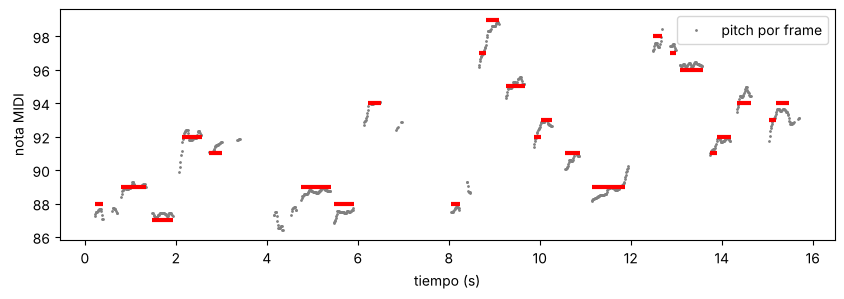

In [5]:
plt.figure(figsize=(10, 3))
plt.plot(tiempos[hay_silbido], midi_suave[hay_silbido], ".", ms=2, color="gray", label="pitch por frame")
for n in notas:
    plt.hlines(n["midi"], n["inicio"], n["fin"], color="red", lw=3)
plt.xlabel("tiempo (s)")
plt.ylabel("nota MIDI")
plt.legend()
plt.show()

La entonación del silbido es floja: varios intervalos salen entre dos semitonos (por ejemplo, un tono entero
silbado a 1.5 semitonos), y al redondear algunas notas caen un semitono arriba o abajo de la canción original.
El criterio del examen es tocar la melodía del silbido, así que se toca lo que se silbó, no la partitura.
Se detectan 24 notas contra las 25 de la canción.

Como el silbido es muy agudo (D6 a D#7), se baja 2 octavas para que el piano toque en su registro, D4 a D#5.
Cada nota dura hasta el inicio de la siguiente, con un máximo de 1 segundo.

In [6]:
TRANSPOSICION = -24
melodia = [n["midi"] + TRANSPOSICION for n in notas]

duraciones = []
for i, n in enumerate(notas):
    if i + 1 < len(notas):
        duraciones.append(min(notas[i + 1]["inicio"] - n["inicio"], 1.0))
    else:
        duraciones.append(n["fin"] - n["inicio"] + 0.3)

print("rango:", nombre_nota(min(melodia)), "a", nombre_nota(max(melodia)))
print("notas:", len(melodia), "| duración total:", round(sum(duraciones), 1), "s")

rango: D#4 a D#5
notas: 24 | duración total: 13.4 s


## 2. Cromosoma (Rol 1)

Un individuo es un vector de 12 números: el piano sintético, sin las notas. Internamente todos los genes viven en
[0, 1] y `decodificar` los escala a su rango físico. Así cruce y mutación usan la misma escala para todos
los genes y un hijo que se sale del rango se corrige con un recorte.

In [7]:
GENES = [
    ("a2", 0.0, 1.0, "amplitud del armónico 2"),
    ("a3", 0.0, 1.0, "amplitud del armónico 3"),
    ("a4", 0.0, 1.0, "amplitud del armónico 4"),
    ("a5", 0.0, 1.0, "amplitud del armónico 5"),
    ("a6", 0.0, 1.0, "amplitud del armónico 6"),
    ("ataque", 0.001, 0.03, "tiempo de subida del golpe (s)"),
    ("tau_rapido", 0.05, 0.6, "caída inicial (s)"),
    ("tau_lento", 0.3, 3.0, "caída final (s)"),
    ("m", 0.0, 1.0, "peso de la caída rápida"),
    ("s", 0.0, 1.0, "cuánto antes mueren los armónicos agudos"),
    ("B", 0.0, 0.002, "inarmonicidad"),
    ("ruido", 0.0, 0.1, "ruido del golpe del martillo"),
]
N_GENES = len(GENES)
MINIMOS = np.array([g[1] for g in GENES])
MAXIMOS = np.array([g[2] for g in GENES])

def codificar(valores):
    return (np.asarray(valores, dtype=float) - MINIMOS) / (MAXIMOS - MINIMOS)

def decodificar(cromosoma):
    c = np.clip(cromosoma, 0, 1)
    return MINIMOS + c * (MAXIMOS - MINIMOS)

pd.DataFrame(GENES, columns=["gen", "mínimo", "máximo", "qué controla"])

,gen,mínimo,máximo,qué controla
0,a2,0.000,1.000,amplitud del armónico 2
1,a3,0.000,1.000,amplitud del armónico 3
2,a4,0.000,1.000,amplitud del armónico 4
3,a5,0.000,1.000,amplitud del armónico 5
4,a6,0.000,1.000,amplitud del armónico 6
5,ataque,0.001,0.030,tiempo de subida del golpe (s)
6,tau_rapido,0.050,0.600,caída inicial (s)
7,tau_lento,0.300,3.000,caída final (s)
8,m,0.000,1.000,peso de la caída rápida
9,s,0.000,1.000,cuánto antes mueren los armónicos agudos


In [8]:
x = MINIMOS + rng.random(N_GENES) * (MAXIMOS - MINIMOS)
assert np.allclose(decodificar(codificar(x)), x)
print("decodificar(codificar(x)) == x: ok")
print("instrumentos posibles con 100 niveles por gen:", f"{100 ** N_GENES:.0e}")

decodificar(codificar(x)) == x: ok
instrumentos posibles con 100 niveles por gen: 1e+24


## 3. Síntesis del instrumento (Rol 2)

Síntesis aditiva con 6 armónicos. Cada armónico tiene una caída doble (rápida y lenta) y los agudos mueren antes.
El ruido del golpe es siempre la misma tira de números aleatorios, para que evaluar el mismo individuo dos veces
dé el mismo fitness.

In [9]:
RUIDO = np.random.default_rng(SEMILLA).standard_normal(SR // 10)
N_ARMONICOS = 6

def sintetizar_nota(f0, dur, p):
    n = int(round(dur * SR))
    t = np.arange(n) / SR
    amp = np.concatenate(([1.0], p[:5]))
    ataque, tau_r, tau_l, m, s, B, ruido = p[5:]
    x = np.zeros(n)
    for k in range(1, N_ARMONICOS + 1):
        fk = k * f0 * np.sqrt(1 + B * k ** 2)
        if fk > 0.45 * SR:
            break
        mas_rapido = 1 + s * (k - 1)
        env = m * np.exp(-t * mas_rapido / tau_r) + (1 - m) * np.exp(-t * mas_rapido / tau_l)
        x += amp[k - 1] * env * np.sin(2 * np.pi * fk * t)
    x *= np.minimum(1.0, t / ataque)
    golpe = min(n, len(RUIDO))
    x[:golpe] += ruido * RUIDO[:golpe] * np.exp(-t[:golpe] / 0.01)
    return x

def sintetizar_instrumento(notas, duraciones, gen):
    p = decodificar(gen)
    trozos = []
    for midi_nota, dur in zip(notas, duraciones):
        if midi_nota is None:
            trozos.append(np.zeros(int(round(dur * SR))))
            continue
        f0 = 440 * 2 ** ((midi_nota - 69) / 12)
        x = sintetizar_nota(f0, dur, p)
        f = min(len(x), int(0.03 * SR))
        x[-f:] *= np.linspace(1, 0, f)
        trozos.append(x)
    return np.concatenate(trozos)

## 4. Fitness (Rol 2)

Se compara el espectrograma (STFT en dB) de cada nota sintetizada con el de la nota real de piano.
Ambas señales se normalizan al mismo pico, así lo que cuenta es el timbre y la caída, no el volumen.

- **Métrica A:** error absoluto medio en dB, `F_A = 1 / (1 + d/10)`. Vale 1 si son idénticas.
- **Métrica B:** correlación de Pearson entre los espectrogramas en dB, `F_B = (1 + r) / 2`.

In [10]:
REF_NOTAS = {62: "piano_D4.wav", 65: "piano_F4.wav", 69: "piano_A4.wav",
             72: "piano_C5.wav", 74: "piano_D5.wav"}
refs = {m: leer_wav(nombre)[:2 * SR] for m, nombre in REF_NOTAS.items()}

def stft_db(x):
    x = x / (np.abs(x).max() + 1e-12)
    f, t, Z = stft(x, SR, nperseg=1024, noverlap=768)
    db = 20 * np.log10(np.abs(Z[f <= 8000]) + 1e-10)
    return np.maximum(db, db.max() - 80)

refs_db = {m: stft_db(x) for m, x in refs.items()}

def fitness(gen, metrica="A"):
    errores, corrs = [], []
    for m, db_ref in refs_db.items():
        db = stft_db(sintetizar_instrumento([m], [2.0], gen))
        errores.append(np.mean(np.abs(db - db_ref)))
        corrs.append(np.nan_to_num(np.corrcoef(db.ravel(), db_ref.ravel())[0, 1]))
    if metrica == "A":
        return 1 / (1 + np.mean(errores) / 10)
    return (1 + np.mean(corrs)) / 2

### Individuo de referencia

Para probar el fitness hace falta un individuo razonable. Sus armónicos y sus tiempos de caída se miden en el
piano real: amplitud de cada armónico cerca de `k·f0` y pendiente del logaritmo de la envolvente. Se usa la mediana
de las 5 notas porque D4 tiene la fundamental más débil que el segundo armónico (es normal en el piano) y distorsiona
el promedio. Los demás genes se fijan a mano.

In [11]:
def medir_piano():
    armonicos, taus_r, taus_l = [], [], []
    for m, x in refs.items():
        f0 = 440 * 2 ** ((m - 69) / 12)
        seg = x[int(0.05 * SR):int(0.55 * SR)]
        esp = np.abs(np.fft.rfft(seg * np.hanning(len(seg))))
        fr = np.fft.rfftfreq(len(seg), 1 / SR)
        picos = [esp[(fr > k * f0 * 0.98) & (fr < k * f0 * 1.02)].max() for k in range(1, 7)]
        armonicos.append(np.array(picos) / picos[0])
        v = int(0.02 * SR)
        env = np.array([np.sqrt(np.mean(x[i:i + v] ** 2)) for i in range(0, len(x) - v, v)])
        t = np.arange(len(env)) * 0.02
        ipico = int(np.argmax(env))
        pend_r = np.polyfit(t[ipico:ipico + 15], np.log(env[ipico:ipico + 15] + 1e-9), 1)[0]
        pend_l = np.polyfit(t[ipico + 25:ipico + 75], np.log(env[ipico + 25:ipico + 75] + 1e-9), 1)[0]
        taus_r.append(-1 / pend_r)
        taus_l.append(-1 / pend_l)
    return np.median(armonicos, axis=0), np.median(taus_r), np.median(taus_l)

arm_med, tau_r_med, tau_l_med = medir_piano()
print("armónicos 2 a 6:", np.round(arm_med[1:], 2))
print("tau rápido:", round(tau_r_med, 2), "s | tau lento:", round(tau_l_med, 2), "s")

armónicos 2 a 6: [0.11 0.09 0.08 0.03 0.02]
tau rápido: 0.23 s | tau lento: 0.99 s


In [12]:
GEN_REFERENCIA = codificar([*arm_med[1:], 0.005, tau_r_med, np.clip(tau_l_med, 0.3, 3.0),
                            0.5, 0.5, 0.0005, 0.02])
print(np.round(decodificar(GEN_REFERENCIA), 4))

[1.055e-01 8.780e-02 8.200e-02 3.260e-02 1.540e-02 5.000e-03 2.303e-01
 9.917e-01 5.000e-01 5.000e-01 5.000e-04 2.000e-02]


### Prueba del fitness

Se compara el individuo de referencia contra una población inicial al azar de 60 individuos (el tamaño base del AG).
El mejor de esos 60 es el Gen 0, el punto de partida de la evolución. Un buen fitness debería darle a la referencia
más aptitud que a casi todos los aleatorios, y las dos métricas deberían estar de acuerdo.

In [13]:
import time

poblacion0 = rng.random((60, N_GENES))
fit_A = np.array([fitness(g, "A") for g in poblacion0])
fit_B = np.array([fitness(g, "B") for g in poblacion0])

ref_A, ref_B = fitness(GEN_REFERENCIA, "A"), fitness(GEN_REFERENCIA, "B")
print("referencia  F_A: %.3f  F_B: %.3f" % (ref_A, ref_B))
print("aleatorios  F_A: media %.3f, máx %.3f | F_B: media %.3f, máx %.3f" %
      (fit_A.mean(), fit_A.max(), fit_B.mean(), fit_B.max()))
print("aleatorios peores que la referencia (F_A): %d de 60" % (fit_A < ref_A).sum())
print("correlación entre F_A y F_B en los aleatorios: %.2f" % np.corrcoef(fit_A, fit_B)[0, 1])

ini = time.time()
for g in poblacion0[:10]:
    fitness(g)
print("tiempo por evaluación: %.0f ms" % ((time.time() - ini) / 10 * 1000))

referencia  F_A: 0.660  F_B: 0.895
aleatorios  F_A: media 0.573, máx 0.685 | F_B: media 0.870, máx 0.901
aleatorios peores que la referencia (F_A): 58 de 60
correlación entre F_A y F_B en los aleatorios: -0.04


tiempo por evaluación: 38 ms


### Audio comparativo

Nota A4: piano real, individuo de referencia y Gen 0.

In [14]:
gen0 = poblacion0[np.argmax(fit_A)]
print("Gen 0 tiene F_A =", round(fit_A.max(), 3))

real = refs[69]
sint_ref = sintetizar_instrumento([69], [2.0], GEN_REFERENCIA)
sint_gen0 = sintetizar_instrumento([69], [2.0], gen0)

for nombre, x in [("piano real", real), ("referencia", sint_ref), ("Gen 0", sint_gen0)]:
    print(nombre)
    display(Audio(x / np.abs(x).max() * 0.9, rate=SR))

Gen 0 tiene F_A = 0.685
piano real


referencia


Gen 0


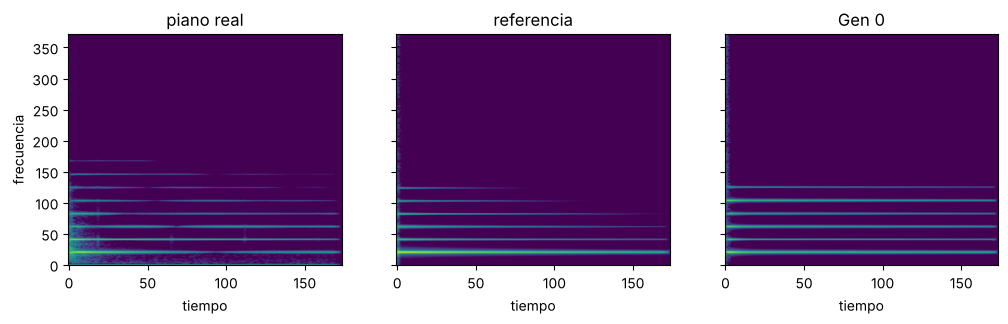

In [15]:
fig, ejes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for eje, titulo, x in zip(ejes, ["piano real", "referencia", "Gen 0"], [real, sint_ref, sint_gen0]):
    eje.imshow(stft_db(x), origin="lower", aspect="auto", vmin=-80, vmax=0)
    eje.set_title(titulo)
    eje.set_xlabel("tiempo")
ejes[0].set_ylabel("frecuencia")
plt.show()

### Primera versión de la melodía

La melodía del silbido (24 notas, bajada 2 octavas) tocada con el individuo de referencia y con el Gen 0.
La versión final va a ser la del mejor individuo evolucionado.

In [16]:
import os
os.makedirs("salidas", exist_ok=True)

def guardar(nombre, x):
    x = x / np.abs(x).max() * 0.9
    wavfile.write("salidas/" + nombre, SR, (x * 32767).astype(np.int16))
    return x

mel_ref = guardar("melodia_referencia.wav", sintetizar_instrumento(melodia, duraciones, GEN_REFERENCIA))
mel_gen0 = guardar("melodia_gen0.wav", sintetizar_instrumento(melodia, duraciones, gen0))

print("referencia")
display(Audio(mel_ref, rate=SR))
print("Gen 0")
display(Audio(mel_gen0, rate=SR))

referencia


Gen 0


## 5. Operadores genéticos

Los operadores son las piezas con las que el AG pasa de una generación a la siguiente: la selección elige quiénes
se reproducen, el cruce mezcla a dos padres y la mutación cambia un poco a los hijos. Los tres trabajan sobre el
cromosoma de 12 genes en [0, 1]. Todos los hijos se recortan a [0, 1] para que siempre sean un piano válido.
Cada operador recibe el generador aleatorio `azar` para que las corridas sean reproducibles.

### Selección por torneo (k = 3)

Se sortean 3 individuos al azar y gana el de mayor aptitud; eso se repite una vez por cada padre que se necesita.
Un individuo malo puede ganar solo si le tocan rivales peores, así que la selección favorece a los buenos pero no
es tan brusca como elegir siempre a los mejores. El tamaño k regula la presión: con k grande ganan casi siempre
los mejores.

In [ ]:
def seleccion_torneo(aptitudes, n, azar, k=3):
    # cada fila son los k rivales de un torneo; gana el de mayor aptitud
    rivales = azar.integers(0, len(aptitudes), size=(n, k))
    return rivales[np.arange(n), np.argmax(aptitudes[rivales], axis=1)]

azar = np.random.default_rng(SEMILLA)
padres = seleccion_torneo(fit_A, 1000, azar)
assert padres.min() >= 0 and padres.max() < len(fit_A)
print("aptitud media de la población: %.3f" % fit_A.mean())
print("aptitud media de los elegidos por torneo: %.3f" % fit_A[padres].mean())

aptitud media de la población: 0.573
aptitud media de los elegidos por torneo: 0.610


### Selección por ruleta

Cada individuo tiene una porción de la ruleta proporcional a su aptitud: si tiene el doble de aptitud, tiene el
doble de probabilidad de ser elegido. Es más natural que el torneo, pero si todas las aptitudes son parecidas
(como al inicio) casi todos tienen la misma probabilidad y la presión es baja. Aquí la aptitud siempre es
positiva, así que se puede usar directo como peso.

In [ ]:
def seleccion_ruleta(aptitudes, n, azar):
    probabilidad = aptitudes / aptitudes.sum()
    return azar.choice(len(aptitudes), size=n, p=probabilidad)

azar = np.random.default_rng(SEMILLA)
padres = seleccion_ruleta(fit_A, 1000, azar)
assert padres.min() >= 0 and padres.max() < len(fit_A)
print("aptitud media de la población: %.3f" % fit_A.mean())
print("aptitud media de los elegidos por ruleta: %.3f" % fit_A[padres].mean())

aptitud media de la población: 0.573
aptitud media de los elegidos por ruleta: 0.577


### Cruce blend-alpha (alpha = 0.3)

Para cada gen se mira el intervalo entre los valores de los dos padres, se lo agranda un 30 % por cada lado y el
hijo toma un valor al azar dentro de ese intervalo. Así el hijo queda cerca de los padres, pero puede salirse un
poco y explorar valores nuevos. Como el intervalo agrandado puede pasar de 0 o de 1, el resultado se recorta.

In [ ]:
def cruce_blend(padre1, padre2, azar, alpha=0.3):
    menor, mayor = np.minimum(padre1, padre2), np.maximum(padre1, padre2)
    ancho = mayor - menor
    bajo, alto = menor - alpha * ancho, mayor + alpha * ancho
    hijo1, hijo2 = azar.uniform(bajo, alto), azar.uniform(bajo, alto)
    return np.clip(hijo1, 0, 1), np.clip(hijo2, 0, 1)

azar = np.random.default_rng(SEMILLA)
hijos = []
for _ in range(500):
    i, j = azar.choice(len(poblacion0), size=2, replace=False)
    hijos.extend(cruce_blend(poblacion0[i], poblacion0[j], azar))
hijos = np.array(hijos)
assert hijos.min() >= 0 and hijos.max() <= 1

# caso extremo: padres en 0 y en 1, donde el recorte hace falta
h1, h2 = cruce_blend(np.zeros(N_GENES), np.ones(N_GENES), azar)
assert 0 <= h1.min() and h1.max() <= 1 and 0 <= h2.min() and h2.max() <= 1
print("hijos en [0, 1]: ok (mín %.3f, máx %.3f)" % (hijos.min(), hijos.max()))

hijos en [0, 1]: ok (mín 0.000, máx 1.000)


### Cruce uniforme

Para cada gen se tira una moneda: el primer hijo copia el gen de un padre o del otro, y el segundo hijo recibe el
que sobró. Mezcla muchísimo a los padres, pero nunca inventa valores nuevos: solo recombina los que ya existen en
la población. Los genes copiados ya están en [0, 1], el recorte es solo por seguridad.

In [ ]:
def cruce_uniforme(padre1, padre2, azar):
    moneda = azar.random(len(padre1)) < 0.5
    hijo1 = np.where(moneda, padre1, padre2)
    hijo2 = np.where(moneda, padre2, padre1)
    return np.clip(hijo1, 0, 1), np.clip(hijo2, 0, 1)

azar = np.random.default_rng(SEMILLA)
hijos = []
for _ in range(500):
    i, j = azar.choice(len(poblacion0), size=2, replace=False)
    h1, h2 = cruce_uniforme(poblacion0[i], poblacion0[j], azar)
    assert np.all((h1 == poblacion0[i]) | (h1 == poblacion0[j]))   # solo copia genes de los padres
    hijos.extend([h1, h2])
hijos = np.array(hijos)
assert hijos.min() >= 0 and hijos.max() <= 1
print("hijos en [0, 1]: ok (mín %.3f, máx %.3f)" % (hijos.min(), hijos.max()))

hijos en [0, 1]: ok (mín 0.002, máx 1.000)


### Mutación gaussiana (sigma = 0.1)

Cada gen se muta con una probabilidad pequeña (aquí un parámetro `prob`). Si le toca, se le suma un número al azar
de una campana de Gauss centrada en 0 con desviación sigma. Casi siempre es un empujón chico, a veces uno
más grande. Sirve para afinar una solución buena sin romperla. Si el gen se pasa de 0 o de 1, se recorta.

In [ ]:
def mutacion_gaussiana(individuo, prob, azar, sigma=0.1):
    toca = azar.random(len(individuo)) < prob
    cambio = azar.normal(0, sigma, len(individuo))
    return np.clip(individuo + toca * cambio, 0, 1)

azar = np.random.default_rng(SEMILLA)
# se prueba con individuos en los bordes (todo 0 y todo 1), donde el recorte hace falta
extremos = np.vstack([np.zeros(N_GENES), np.ones(N_GENES), poblacion0])
mutados = np.array([mutacion_gaussiana(ind, 0.3, azar) for ind in extremos for _ in range(50)])
assert mutados.min() >= 0 and mutados.max() <= 1
cambiados = (mutados != np.repeat(extremos, 50, axis=0)).mean()
print("hijos en [0, 1]: ok | fracción de genes que cambió: %.2f (prob = 0.30)" % cambiados)

hijos en [0, 1]: ok | fracción de genes que cambió: 0.30 (prob = 0.30)


### Mutación uniforme

Igual que antes, cada gen se muta con probabilidad `prob`, pero si le toca se reemplaza por un valor nuevo al
azar en todo [0, 1], sin importar el valor que tenía. Es un salto grande que permite escapar de una zona mala
del espacio de búsqueda, pero también puede arruinar un gen que estaba bien.

In [ ]:
def mutacion_uniforme(individuo, prob, azar):
    toca = azar.random(len(individuo)) < prob
    return np.clip(np.where(toca, azar.random(len(individuo)), individuo), 0, 1)

azar = np.random.default_rng(SEMILLA)
mutados = np.array([mutacion_uniforme(ind, 0.3, azar) for ind in extremos for _ in range(50)])
assert mutados.min() >= 0 and mutados.max() <= 1
cambiados = (mutados != np.repeat(extremos, 50, axis=0)).mean()
print("hijos en [0, 1]: ok | fracción de genes que cambió: %.2f (prob = 0.30)" % cambiados)

hijos en [0, 1]: ok | fracción de genes que cambió: 0.30 (prob = 0.30)


### Mutación no uniforme (sigma de 0.2 a 0.02)

Es la gaussiana, pero con un sigma que baja de 0.2 a 0.02 a medida que pasan las generaciones. Al principio los
cambios son grandes y el AG explora; al final son chiquitos y el AG afina lo que ya encontró. Por eso en cada
llamada hay que decir en qué generación va (`gen`) y cuántas son en total (`max_gen`).

In [ ]:
def sigma_no_uniforme(gen, max_gen, sigma_ini=0.2, sigma_fin=0.02):
    return sigma_ini + (sigma_fin - sigma_ini) * gen / max_gen

def mutacion_no_uniforme(individuo, prob, azar, gen, max_gen):
    return mutacion_gaussiana(individuo, prob, azar, sigma_no_uniforme(gen, max_gen))

azar = np.random.default_rng(SEMILLA)
for gen in (0, 50, 100):
    mutados = np.array([mutacion_no_uniforme(ind, 1.0, azar, gen, 100) for ind in poblacion0])
    assert mutados.min() >= 0 and mutados.max() <= 1
    cambio = np.abs(mutados - poblacion0).mean()
    print("gen %3d: sigma %.3f, cambio medio por gen %.3f, hijos en [0, 1]: ok" %
          (gen, sigma_no_uniforme(gen, 100), cambio))

gen   0: sigma 0.200, cambio medio por gen 0.138, hijos en [0, 1]: ok
gen  50: sigma 0.110, cambio medio por gen 0.080, hijos en [0, 1]: ok
gen 100: sigma 0.020, cambio medio por gen 0.017, hijos en [0, 1]: ok


## 6. Ciclo del AG

Aquí se juntan las piezas: población inicial al azar, evaluación con la métrica A, élite, selección, cruce y
mutación, generación tras generación. La corrida termina a las 100 generaciones o cuando pasan 20 sin que la mejor
aptitud suba más de 0.0001. Opcionalmente hay inmigración: si la diversidad (desviación estándar media de los genes)
cae bajo 0.05, el 10 % peor de la población se reemplaza por individuos nuevos al azar.

La función recibe los operadores por nombre y los demás parámetros de la configuración, y un generador `azar`
con semilla. Los individuos que pasan sin cambios (la élite y los hijos que no se cruzaron ni mutaron) conservan su
aptitud y no se vuelven a evaluar. Devuelve una tabla con la aptitud máxima, la media, la desviación y la
diversidad de cada generación, el mejor individuo y el número de evaluaciones usadas.

In [ ]:
# lo usan los procesos del cálculo en paralelo
SELECCION = {"torneo": lambda apt, n, azar, k: seleccion_torneo(apt, n, azar, k),
             "ruleta": lambda apt, n, azar, k: seleccion_ruleta(apt, n, azar)}
CRUCE = {"blend": cruce_blend, "uniforme": cruce_uniforme}
MUTACION = {"gaussiana": lambda ind, prob, azar, gen, max_gen: mutacion_gaussiana(ind, prob, azar),
            "uniforme": lambda ind, prob, azar, gen, max_gen: mutacion_uniforme(ind, prob, azar),
            "no_uniforme": mutacion_no_uniforme}

def evolucionar(azar, seleccion="torneo", cruce="blend", mutacion="gaussiana", N=60, max_gen=100,
                p_cruce=0.9, p_mut=0.08, elite=2, k=3, inmigracion=False, paciencia=20, mejora_min=0.0001):
    poblacion = azar.random((N, N_GENES))
    aptitud = np.array([fitness(g, "A") for g in poblacion])
    evaluaciones = N
    mejor, mejor_apt = poblacion[aptitud.argmax()].copy(), aptitud.max()
    referencia, sin_mejora = aptitud.max(), 0
    filas = [(0, aptitud.max(), aptitud.mean(), aptitud.std(), poblacion.std(axis=0).mean(), evaluaciones)]

    for gen in range(1, max_gen + 1):
        orden = np.argsort(-aptitud)
        n_pares = (N - elite + 1) // 2
        padres = SELECCION[seleccion](aptitud, 2 * n_pares, azar, k)
        hijos, apt_hijos = [], []
        for i in range(n_pares):
            a, b = padres[2 * i], padres[2 * i + 1]
            if azar.random() < p_cruce:
                par = CRUCE[cruce](poblacion[a], poblacion[b], azar)
            else:
                par = (poblacion[a].copy(), poblacion[b].copy())
            for hijo in par:
                if len(hijos) == N - elite:
                    break
                hijo = MUTACION[mutacion](hijo, p_mut, azar, gen, max_gen)
                # si el hijo quedó igual a un padre se reutiliza su aptitud
                if np.array_equal(hijo, poblacion[a]):
                    apt = aptitud[a]
                elif np.array_equal(hijo, poblacion[b]):
                    apt = aptitud[b]
                else:
                    apt = fitness(hijo, "A")
                    evaluaciones += 1
                hijos.append(hijo)
                apt_hijos.append(apt)
        poblacion = np.vstack([poblacion[orden[:elite]], np.array(hijos)])
        aptitud = np.concatenate([aptitud[orden[:elite]], apt_hijos])

        if inmigracion and poblacion.std(axis=0).mean() < 0.05:
            peores = np.argsort(aptitud)[:int(0.1 * N)]
            poblacion[peores] = azar.random((len(peores), N_GENES))
            aptitud[peores] = [fitness(g, "A") for g in poblacion[peores]]
            evaluaciones += len(peores)

        if aptitud.max() > mejor_apt:
            mejor, mejor_apt = poblacion[aptitud.argmax()].copy(), aptitud.max()
        filas.append((gen, aptitud.max(), aptitud.mean(), aptitud.std(), poblacion.std(axis=0).mean(), evaluaciones))

        if aptitud.max() - referencia > mejora_min:
            referencia, sin_mejora = aptitud.max(), 0
        else:
            sin_mejora += 1
        if sin_mejora >= paciencia:
            break

    historial = pd.DataFrame(filas, columns=["generacion", "maximo", "media", "desviacion", "diversidad", "evaluaciones"])
    return historial, mejor, evaluaciones

### Corrida base

Una corrida con la configuración base (N = 60, élite 2, cruce 0.9, mutación 0.08 por gen, torneo k = 3) y la
combinación C1 (torneo + blend-alpha + gaussiana). Sirve para comprobar que la función funciona.

`RECALCULAR` decide si las corridas largas se vuelven a calcular. Con `False` (lo normal) esta celda lee el historial
de `resultados/combinaciones.csv` (es la corrida C1 con semilla 2026, que tarda unos 10 minutos); con `True` la corre
de nuevo.

In [ ]:
RECALCULAR = False   # True vuelve a correr las corridas largas; False lee los CSV de resultados/

if RECALCULAR:
    inicio = time.time()
    historial, mejor, evaluaciones = evolucionar(np.random.default_rng(SEMILLA))
    assert mejor.min() >= 0 and mejor.max() <= 1
    print("tiempo de la corrida: %.0f s" % (time.time() - inicio))
else:
    base = pd.read_csv("resultados/combinaciones.csv")
    historial = base[(base["combinacion"] == "C1") & (base["semilla"] == SEMILLA)]
    evaluaciones = historial["evaluaciones"].iloc[-1]
    print("historial leído de resultados/combinaciones.csv (C1, semilla %d)" % SEMILLA)

assert evaluaciones < 60 + 100 * 58   # los que pasan sin cambios no se re-evalúan
print("generaciones: %d, evaluaciones: %d" % (historial["generacion"].iloc[-1], evaluaciones))
print("aptitud: Gen 0 %.3f -> final %.3f (referencia %.3f)" % (historial["maximo"].iloc[0], historial["maximo"].iloc[-1], ref_A))

historial leído de resultados/combinaciones.csv (C1, semilla 2026)
generaciones: 73, evaluaciones: 4084
aptitud: Gen 0 0.685 -> final 0.731 (referencia 0.660)


### Comparación de combinaciones

Se comparan tres combinaciones de operadores, cada una con 5 semillas (2026 a 2030) y la configuración base:

- **C1**: torneo + blend-alpha + mutación gaussiana.
- **C2**: ruleta + cruce uniforme + mutación uniforme.
- **C3**: torneo + blend-alpha + mutación no uniforme.

Con la misma semilla las tres combinaciones parten de la misma población inicial, así que la comparación es justa.
Cada corrida tarda minutos, por eso los resultados se guardan en `resultados/combinaciones.csv` y el notebook los
lee si el archivo existe.

In [ ]:
# lo usan los procesos del cálculo en paralelo
COMBINACIONES = {
    "C1": dict(seleccion="torneo", cruce="blend", mutacion="gaussiana"),
    "C2": dict(seleccion="ruleta", cruce="uniforme", mutacion="uniforme"),
    "C3": dict(seleccion="torneo", cruce="blend", mutacion="no_uniforme"),
}
SEMILLAS = [SEMILLA + i for i in range(5)]

def correr_una(nombre, semilla):
    historial, _, _ = evolucionar(np.random.default_rng(semilla), **COMBINACIONES[nombre])
    historial.insert(0, "semilla", semilla)
    historial.insert(0, "combinacion", nombre)
    return historial

### Cálculo en paralelo

Las comparaciones son muchas corridas independientes, así que con `RECALCULAR = True` se reparten entre todos los
núcleos con `multiprocessing`. En Windows cada proceso arranca vacío y no puede recibir funciones definidas en el
notebook, por eso `en_paralelo` escribe un pequeño módulo que, en cada proceso, vuelve a leer este notebook y
ejecuta sus celdas de definiciones (la parte 1, los operadores y las que empiezan con la marca
`# lo usan los procesos`). Las corridas se entregan una por una apenas terminan.

In [ ]:
import multiprocessing as mp
import os, sys, tempfile

NOTEBOOK = "silbido_piano.ipynb"

# código de cada proceso: lee el notebook y ejecuta solo las celdas de definiciones
CODIGO_PROCESO = '''
import contextlib, io, json, os
G = {"__name__": "proceso"}

def iniciar(notebook):
    os.environ["MPLBACKEND"] = "Agg"
    celdas = json.load(open(notebook, encoding="utf8"))["cells"]
    en_seccion_6 = False
    with contextlib.redirect_stdout(io.StringIO()):
        for celda in celdas:
            texto = "".join(celda["source"])
            if celda["cell_type"] == "markdown" and texto.startswith("## 6."):
                en_seccion_6 = True
            if celda["cell_type"] != "code" or "wavfile.write" in texto:
                continue   # las celdas que guardan audios no se repiten en cada proceso
            if not en_seccion_6 or texto.startswith("# lo usan los procesos"):
                exec(texto, G)

def tarea(pedido):
    nombre, argumentos = pedido
    return argumentos, G[nombre](*argumentos)
'''

def en_paralelo(pedidos):
    # pedidos: lista de (nombre de la función, argumentos); entrega (argumentos, resultado) apenas termina cada uno
    carpeta = os.path.join(tempfile.gettempdir(), "proceso_ag")
    os.makedirs(carpeta, exist_ok=True)
    with open(os.path.join(carpeta, "proceso_ag.py"), "w", encoding="utf8") as f:
        f.write(CODIGO_PROCESO)
    if carpeta not in sys.path:
        sys.path.insert(0, carpeta)
    import proceso_ag
    with mp.Pool(os.cpu_count(), initializer=proceso_ag.iniciar, initargs=(NOTEBOOK,)) as pool:
        yield from pool.imap_unordered(proceso_ag.tarea, pedidos)

In [ ]:
import os

ARCHIVO = "resultados/combinaciones.csv"

if RECALCULAR or not os.path.exists(ARCHIVO):
    pedidos = [("correr_una", (n, s)) for n in COMBINACIONES for s in SEMILLAS]
    corridas = dict(en_paralelo(pedidos))
    comb = pd.concat([corridas[args] for _, args in pedidos], ignore_index=True)
    comb.to_csv(ARCHIVO, index=False)
else:
    comb = pd.read_csv(ARCHIVO)
print("corridas:", comb.groupby(["combinacion", "semilla"]).ngroups, "| filas:", len(comb))

corridas: 15 | filas: 1091


### Tabla comparativa

Para cada corrida se toma la aptitud final (la mejor de la última generación) y dos tiempos de convergencia: la
primera generación en que la aptitud máxima llegó al 90 % de esa aptitud final, y la primera en que recorrió el
90 % de la mejora entre el Gen 0 y el final. El primero sale casi siempre 0, porque el mejor del Gen 0 ya está
cerca del final; el segundo es el que distingue a las combinaciones. La tabla promedia las 5 semillas.

In [ ]:
filas = []
for (nombre, semilla), d in comb.groupby(["combinacion", "semilla"]):
    final = d["maximo"].iloc[-1]
    gen90 = d.loc[d["maximo"] >= 0.9 * final, "generacion"].iloc[0]
    # 90 % de la mejora: de la aptitud del Gen 0 a la final
    meta = d["maximo"].iloc[0] + 0.9 * (final - d["maximo"].iloc[0])
    gen90m = d.loc[d["maximo"] >= meta, "generacion"].iloc[0]
    filas.append((nombre, final, gen90, gen90m, d["generacion"].iloc[-1], d["evaluaciones"].iloc[-1]))
por_corrida = pd.DataFrame(filas, columns=["combinacion", "final", "gen90", "gen90m", "generaciones", "evaluaciones"])

g = por_corrida.groupby("combinacion")
tabla = pd.DataFrame({
    "aptitud final (media)": g["final"].mean(),
    "desviación": g["final"].std(),
    "mejor corrida": g["final"].max(),
    "generaciones hasta 90 % del máximo": g["gen90"].mean(),
    "generaciones hasta 90 % de la mejora": g["gen90m"].mean(),
    "generaciones usadas": g["generaciones"].mean(),
    "evaluaciones": g["evaluaciones"].mean(),
}).round(3)
tabla

,aptitud final (media),desviación,mejor corrida,generaciones hasta 90 % del máximo,generaciones hasta 90 % de la mejora,generaciones usadas,evaluaciones
combinacion,,,,,,,
C1,0.732,0.001,0.732,0.0,13.4,69.6,3890.2
C2,0.725,0.002,0.727,0.0,26.8,60.8,3424.6
C3,0.732,0.000,0.732,0.0,12.8,84.8,4732.0


### Figuras del informe

Las gráficas que usa el informe se guardan además en `informe/figuras/`, así que salen siempre de este notebook.

In [ ]:
os.makedirs("informe/figuras", exist_ok=True)

def guardar_figura(nombre):
    plt.savefig("informe/figuras/" + nombre, dpi=150, bbox_inches="tight")

### Diversidad por generación

Diversidad = desviación estándar media de los genes de la población. Cada línea gruesa es el promedio de las 5
semillas (en las últimas generaciones solo quedan las corridas que no habían parado) y las finas son cada semilla.

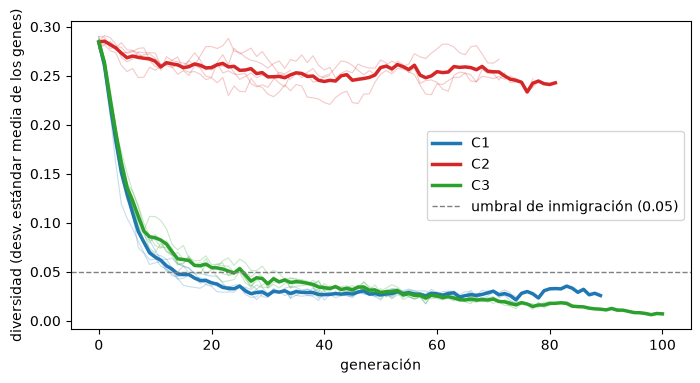

In [ ]:
colores = {"C1": "tab:blue", "C2": "tab:red", "C3": "tab:green"}
plt.figure(figsize=(8, 4))
for nombre, d in comb.groupby("combinacion"):
    for semilla, c in d.groupby("semilla"):
        plt.plot(c["generacion"], c["diversidad"], color=colores[nombre], alpha=0.25, lw=0.8)
    media = d.groupby("generacion")["diversidad"].mean()
    plt.plot(media.index, media.values, color=colores[nombre], lw=2.5, label=nombre)
plt.axhline(0.05, color="gray", ls="--", lw=1, label="umbral de inmigración (0.05)")
plt.xlabel("generación")
plt.ylabel("diversidad (desv. estándar media de los genes)")
plt.legend()
guardar_figura("diversidad_combinaciones.png")
plt.show()

## 7. Configuraciones

Se mide cómo cambia el AG al mover un parámetro a la vez desde la configuración base: población (20, 60, 150),
probabilidad de cruce (0.5, 0.9, 0.95), mutación por gen (0.02, 0.08, 0.3), élite (0, 2, 6), tamaño del torneo
(2, 3, 5) e inmigración (no, sí). Son 12 configuraciones (1 base y 11 variaciones), cada una con 3 semillas: 36
corridas. Todas usan los operadores de C1 (torneo, blend-alpha y gaussiana).

Son horas de cálculo, así que cada corrida se guarda en `resultados/configs.csv` apenas termina. Si algo falla, al
volver a lanzar solo se corren las que faltan (para rehacer todo hay que borrar ese archivo). Las corridas no se
lanzan solas: hay que poner `CORRER_CONFIGS = True`.

In [ ]:
# lo usan los procesos del cálculo en paralelo
OPERADORES = COMBINACIONES["C1"]
BASE = dict(N=60, max_gen=100, p_cruce=0.9, p_mut=0.08, elite=2, k=3, inmigracion=False)

CONFIGS = {"base": BASE}
for parametro, valores in [("N", [20, 150]), ("p_cruce", [0.5, 0.95]), ("p_mut", [0.02, 0.3]),
                           ("elite", [0, 6]), ("k", [2, 5])]:
    for valor in valores:
        CONFIGS["%s=%s" % (parametro, valor)] = {**BASE, parametro: valor}
CONFIGS["inmigracion"] = {**BASE, "inmigracion": True}
SEMILLAS_CONFIG = [SEMILLA + i for i in range(3)]
assert len(CONFIGS) == 12

def correr_config(nombre, semilla):
    historial, _, _ = evolucionar(np.random.default_rng(semilla), **OPERADORES, **CONFIGS[nombre])
    historial.insert(0, "semilla", semilla)
    historial.insert(0, "config", nombre)
    return historial

pd.DataFrame(CONFIGS).T

,N,max_gen,p_cruce,p_mut,elite,k,inmigracion
base,60,100,0.9,0.08,2,3,False
N=20,20,100,0.9,0.08,2,3,False
N=150,150,100,0.9,0.08,2,3,False
p_cruce=0.5,60,100,0.5,0.08,2,3,False
p_cruce=0.95,60,100,0.95,0.08,2,3,False
p_mut=0.02,60,100,0.9,0.02,2,3,False
p_mut=0.3,60,100,0.9,0.3,2,3,False
elite=0,60,100,0.9,0.08,0,3,False
elite=6,60,100,0.9,0.08,6,3,False
k=2,60,100,0.9,0.08,2,2,False


In [ ]:
CORRER_CONFIGS = False   # True lanza (o retoma) las corridas que falten; son 36 y tardan horas
ARCHIVO_CONFIGS = "resultados/configs.csv"

hechas = set()
if os.path.exists(ARCHIVO_CONFIGS):
    previas = pd.read_csv(ARCHIVO_CONFIGS)
    hechas = set(zip(previas["config"], previas["semilla"]))
pendientes = [(n, s) for s in SEMILLAS_CONFIG for n in CONFIGS if (n, s) not in hechas]
pendientes.sort(key=lambda t: -CONFIGS[t[0]]["N"])   # primero las de población grande, que son las más lentas

if pendientes and CORRER_CONFIGS:
    inicio = time.time()
    for (nombre, semilla), historial in en_paralelo([("correr_config", t) for t in pendientes]):
        # cada corrida se guarda apenas termina
        historial.to_csv(ARCHIVO_CONFIGS, mode="a", header=not os.path.exists(ARCHIVO_CONFIGS), index=False)
        hechas.add((nombre, semilla))
        print("%s, semilla %d lista (%d de %d, %.0f min)" %
              (nombre, semilla, len(hechas), len(CONFIGS) * len(SEMILLAS_CONFIG), (time.time() - inicio) / 60))
else:
    print("corridas guardadas: %d de %d" % (len(hechas), len(CONFIGS) * len(SEMILLAS_CONFIG)))
    if pendientes:
        print("faltan %d; CORRER_CONFIGS = True las lanza" % len(pendientes))

corridas guardadas: 36 de 36


### Tabla de configuraciones

Cada fila es una configuración (media de sus 3 semillas). Las columnas son la aptitud final, su desviación entre
semillas, las generaciones que tardó en recorrer el 90 % de la mejora entre el Gen 0 y el final, las generaciones
y evaluaciones totales y la diversidad con la que terminó la población.

In [ ]:
filas = []
for (nombre, semilla), d in pd.read_csv(ARCHIVO_CONFIGS).groupby(["config", "semilla"]):
    final = d["maximo"].iloc[-1]
    meta = d["maximo"].iloc[0] + 0.9 * (final - d["maximo"].iloc[0])
    gen90 = d.loc[d["maximo"] >= meta, "generacion"].iloc[0]
    filas.append((nombre, final, gen90, d["generacion"].iloc[-1], d["evaluaciones"].iloc[-1], d["diversidad"].iloc[-1]))
por_config = pd.DataFrame(filas, columns=["config", "final", "gen90", "generaciones", "evaluaciones", "diversidad"])

grupo = por_config.groupby("config")
tabla_configs = pd.DataFrame({
    "aptitud final (media)": grupo["final"].mean(),
    "desviación": grupo["final"].std(),
    "generaciones hasta 90 % de la mejora": grupo["gen90"].mean(),
    "generaciones usadas": grupo["generaciones"].mean(),
    "evaluaciones": grupo["evaluaciones"].mean(),
    "diversidad final": grupo["diversidad"].mean(),
}).round(3).loc[list(CONFIGS)]
tabla_configs

,aptitud final (media),desviación,generaciones hasta 90 % de la mejora,generaciones usadas,evaluaciones,diversidad final
config,,,,,,
base,0.732,0.001,13.333,69.000,3855.333,0.026
N=20,0.731,0.000,23.333,85.333,1442.000,0.022
N=150,0.733,0.000,16.000,85.000,12196.000,0.028
p_cruce=0.5,0.732,0.000,20.667,68.333,3254.333,0.024
p_cruce=0.95,0.732,0.000,13.667,80.667,4603.333,0.028
p_mut=0.02,0.731,0.001,19.667,90.000,4718.667,0.009
p_mut=0.3,0.732,0.000,15.000,73.333,4305.667,0.078
elite=0,0.732,0.001,16.000,91.667,5319.333,0.029
elite=6,0.732,0.001,17.000,80.000,4171.333,0.026


### Convergencia de las configuraciones

Aptitud máxima contra evaluaciones gastadas (promedio de las 3 semillas). Se usan evaluaciones y no generaciones
porque cambiar la población cambia cuánto cuesta cada generación. Cada cuadro mueve un solo parámetro y la línea
negra es siempre la configuración base.

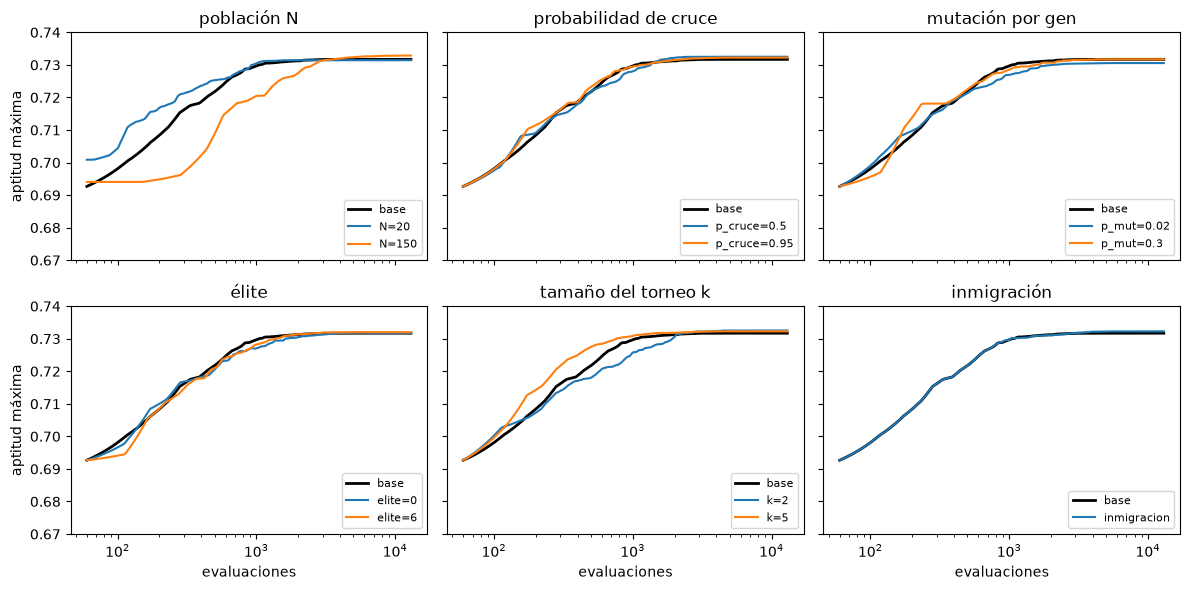

In [ ]:
factores = {"población N": ["N=20", "N=150"], "probabilidad de cruce": ["p_cruce=0.5", "p_cruce=0.95"],
            "mutación por gen": ["p_mut=0.02", "p_mut=0.3"], "élite": ["elite=0", "elite=6"],
            "tamaño del torneo k": ["k=2", "k=5"], "inmigración": ["inmigracion"]}
corridas_cfg = pd.read_csv(ARCHIVO_CONFIGS)
malla = np.geomspace(60, 13000, 200)

def curva(nombre):
    # aptitud máxima promedio en una malla de evaluaciones común
    ys = [np.interp(malla, c["evaluaciones"], c["maximo"]) for _, c in corridas_cfg[corridas_cfg["config"] == nombre].groupby("semilla")]
    return np.mean(ys, axis=0)

fig, ejes = plt.subplots(2, 3, figsize=(12, 6), sharex=True, sharey=True)
for eje, (titulo, nombres) in zip(ejes.ravel(), factores.items()):
    eje.plot(malla, curva("base"), color="black", lw=2, label="base")
    for nombre, color in zip(nombres, ["tab:blue", "tab:orange"]):
        eje.plot(malla, curva(nombre), color=color, lw=1.5, label=nombre)
    eje.set_title(titulo)
    eje.set_xscale("log")
    eje.set_ylim(0.67, 0.74)
    eje.legend(fontsize=8, loc="lower right")
for eje in ejes[1]:
    eje.set_xlabel("evaluaciones")
for eje in ejes[:, 0]:
    eje.set_ylabel("aptitud máxima")
plt.tight_layout()
guardar_figura("convergencia_configuraciones.png")
plt.show()

## 8. Meta-evaluación

El AG usa azar, así que una sola corrida no dice qué tan bien funciona en general. Aquí se repite la configuración
base (N = 60, élite 2, cruce 0.9, mutación 0.08, torneo k = 3, operadores de C1) con 10 semillas distintas, de la
101 a la 110, y después se compara con una búsqueda aleatoria y se analiza el mejor individuo.

Cada corrida se guarda en `resultados/meta.csv` apenas termina. Además del historial por generación, cada fila trae
los 12 genes del mejor individuo de su corrida (columnas `mejor_*`). Las corridas no se lanzan solas: hay que poner
`CORRER_META = True`.

In [ ]:
# lo usan los procesos del cálculo en paralelo
SEMILLAS_META = list(range(101, 111))

def correr_meta(semilla):
    # configuración base con los operadores de C1; además del historial guarda el mejor individuo de la corrida
    historial, mejor, _ = evolucionar(np.random.default_rng(semilla), **OPERADORES, **BASE)
    historial.insert(0, "semilla", semilla)
    for (nombre, *_), valor in zip(GENES, mejor):
        historial["mejor_" + nombre] = valor
    return historial

In [ ]:
CORRER_META = False   # True lanza (o retoma) las corridas que falten
ARCHIVO_META = "resultados/meta.csv"

hechas_meta = set(pd.read_csv(ARCHIVO_META)["semilla"]) if os.path.exists(ARCHIVO_META) else set()
faltan_meta = [s for s in SEMILLAS_META if s not in hechas_meta]

if faltan_meta and CORRER_META:
    inicio = time.time()
    for (semilla,), historial in en_paralelo([("correr_meta", (s,)) for s in faltan_meta]):
        # cada corrida se guarda apenas termina
        historial.to_csv(ARCHIVO_META, mode="a", header=not os.path.exists(ARCHIVO_META), index=False)
        hechas_meta.add(semilla)
        print("semilla %d lista (%d de %d, %.0f min)" % (semilla, len(hechas_meta), len(SEMILLAS_META), (time.time() - inicio) / 60))
else:
    print("corridas guardadas: %d de %d" % (len(hechas_meta), len(SEMILLAS_META)))
    if faltan_meta:
        print("faltan %d; CORRER_META = True las lanza" % len(faltan_meta))

corridas guardadas: 0 de 10
faltan 10; CORRER_META = True las lanza


### Baseline: búsqueda aleatoria

Para saber si el AG sirve hay que compararlo con lo más simple: probar individuos al azar y quedarse con el mejor. Se
hace con 10 semillas y 6000 evaluaciones cada una. La aptitud de lo que lleva encontrado a las 3855 evaluaciones (las
que gasta en promedio la configuración base) sale del mismo flujo: es el mejor de las primeras 3855 pruebas, igual que
si se hubiera parado ahí.

Las 6000 evaluaciones de cada semilla se reparten en trozos de 1000 entre los núcleos y se guardan cada una en
`resultados/azar.csv` (semilla, número de evaluación, aptitud). Tampoco se lanzan solas: `CORRER_AZAR = True`.

In [ ]:
# lo usan los procesos del cálculo en paralelo
EVALS_AZAR, TROZO = 6000, 1000

def evaluar_azar(semilla, desde, hasta):
    # los individuos de una semilla salen siempre del mismo flujo aleatorio; se evalúan por trozos para repartirlos
    individuos = np.random.default_rng(semilla).random((EVALS_AZAR, N_GENES))[desde:hasta]
    aptitudes = [fitness(g, "A") for g in individuos]
    return pd.DataFrame({"semilla": semilla, "evaluacion": np.arange(desde + 1, hasta + 1), "aptitud": aptitudes})

In [ ]:
CORRER_AZAR = False   # True lanza (o retoma) los trozos que falten
ARCHIVO_AZAR = "resultados/azar.csv"

hechos = set()
if os.path.exists(ARCHIVO_AZAR):
    previo = pd.read_csv(ARCHIVO_AZAR)
    hechos = set(zip(previo["semilla"], (previo["evaluacion"] - 1) // TROZO * TROZO))
trozos = [(s, d, d + TROZO) for s in SEMILLAS_META for d in range(0, EVALS_AZAR, TROZO)]
faltan_azar = [t for t in trozos if (t[0], t[1]) not in hechos]

if faltan_azar and CORRER_AZAR:
    inicio = time.time()
    for (semilla, desde, hasta), trozo in en_paralelo([("evaluar_azar", t) for t in faltan_azar]):
        trozo.to_csv(ARCHIVO_AZAR, mode="a", header=not os.path.exists(ARCHIVO_AZAR), index=False)
        hechos.add((semilla, desde))
        print("semilla %d, evaluaciones %d a %d lista (%d de %d, %.0f min)" %
              (semilla, desde + 1, hasta, len(hechos), len(trozos), (time.time() - inicio) / 60))
else:
    print("trozos guardados: %d de %d" % (len(hechos), len(trozos)))
    if faltan_azar:
        print("faltan %d; CORRER_AZAR = True los lanza" % len(faltan_azar))

trozos guardados: 0 de 60
faltan 60; CORRER_AZAR = True los lanza


### Las 10 corridas

Resultado de cada semilla (aptitud final, generaciones y evaluaciones usadas), con la media y la desviación estándar
de las 10 corridas, y un boxplot de la aptitud final.

In [ ]:
meta = pd.read_csv(ARCHIVO_META)
ultima = meta.groupby("semilla").last()
tabla_meta = pd.DataFrame({"aptitud final": ultima["maximo"], "generaciones": ultima["generacion"],
                           "evaluaciones": ultima["evaluaciones"]})
for columna in tabla_meta:
    print("%-13s %.4f ± %.4f" % (columna, tabla_meta[columna].mean(), tabla_meta[columna].std()))
tabla_meta.round(4)

aptitud final 0.7321 ± 0.0005
generaciones  80.0000 ± 17.0555
evaluaciones  4480.8000 ± 942.6780


,aptitud final,generaciones,evaluaciones
semilla,,,
101,0.7319,83,4637
102,0.7317,100,5596
103,0.7317,100,5588
104,0.7327,67,3760
105,0.7318,100,5603
106,0.7319,69,3839
107,0.7314,87,4847
108,0.7324,65,3663
109,0.7322,51,2900


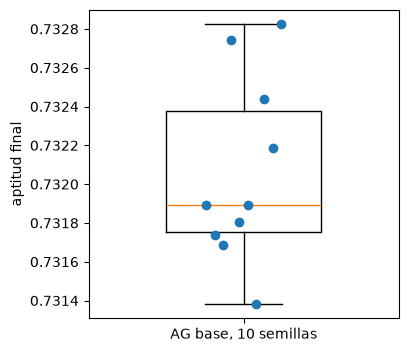

In [ ]:
plt.figure(figsize=(4, 4))
plt.boxplot(tabla_meta["aptitud final"], widths=0.5)
plt.scatter(1 + np.linspace(-0.12, 0.12, len(tabla_meta)), tabla_meta["aptitud final"], color="tab:blue", zorder=3)
plt.xticks([1], ["AG base, 10 semillas"])
plt.ylabel("aptitud final")
plt.show()

### AG contra búsqueda aleatoria

Para cada semilla del azar se toma la mejor aptitud encontrada hasta una cierta evaluación (la aptitud máxima
acumulada). Se compara con la aptitud final del AG en dos puntos: a las 3855 evaluaciones, que es lo que gasta en
promedio la configuración base, y a las 6000. El test de Mann-Whitney exacto (una cola, el AG mayor que el azar) no supone
que los datos sean normales, que es lo prudente con solo 10 valores por grupo.

In [ ]:
azar = pd.read_csv(ARCHIVO_AZAR).sort_values(["semilla", "evaluacion"])
azar["mejor"] = azar.groupby("semilla")["aptitud"].cummax()
EVALS_BASE = int(round(tabla_configs.loc["base", "evaluaciones"]))   # promedio de la tabla de configuraciones

from scipy.stats import mannwhitneyu
ag = tabla_meta["aptitud final"]
filas = []
for n in (EVALS_BASE, EVALS_AZAR):
    mejores = azar[azar["evaluacion"] == n].set_index("semilla")["mejor"]
    u, p = mannwhitneyu(ag, mejores, alternative="greater", method="exact")
    filas.append(("azar con %d evaluaciones" % n, round(ag.mean(), 4), round(mejores.mean(), 4),
                  round(mejores.std(), 4), u, p))
pd.DataFrame(filas, columns=["comparación con el AG", "AG (media)", "azar (media)", "azar (desv.)", "U", "p"])

,comparación con el AG,AG (media),azar (media),azar (desv.),U,p
0,azar con 3855 evaluaciones,0.7321,0.7140,0.0036,100.0,0.000005
1,azar con 6000 evaluaciones,0.7321,0.7164,0.0032,100.0,0.000005


Mejor aptitud acumulada contra las evaluaciones gastadas: línea = media de las 10 semillas y banda = una desviación
estándar. El AG deja de gastar evaluaciones cuando se cumple su criterio de parada, y desde ahí su línea queda plana.

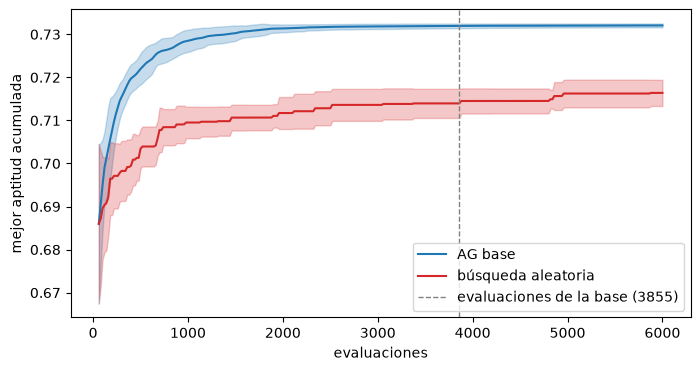

In [ ]:
malla = np.arange(60, EVALS_AZAR + 1, 20)
curvas_ag = np.array([np.interp(malla, c["evaluaciones"], c["maximo"]) for _, c in meta.groupby("semilla")])
curvas_azar = azar.pivot(index="evaluacion", columns="semilla", values="mejor").loc[malla].to_numpy().T

plt.figure(figsize=(8, 4))
for nombre, curvas, color in [("AG base", curvas_ag, "tab:blue"), ("búsqueda aleatoria", curvas_azar, "tab:red")]:
    media, desv = curvas.mean(axis=0), curvas.std(axis=0)
    plt.plot(malla, media, color=color, label=nombre)
    plt.fill_between(malla, media - desv, media + desv, color=color, alpha=0.25)
plt.axvline(EVALS_BASE, color="gray", ls="--", lw=1, label="evaluaciones de la base (%d)" % EVALS_BASE)
plt.xlabel("evaluaciones")
plt.ylabel("mejor aptitud acumulada")
plt.legend(loc="lower right")
guardar_figura("ag_vs_azar.png")
plt.show()

### Tornado: qué genes importan

Se parte del mejor individuo de las 10 corridas y se mueve cada gen un 10 % de su rango, hacia abajo y hacia arriba,
dejando los demás quietos (si el gen está cerca de un borde, el movimiento se recorta a [0, 1]). El gráfico muestra
cuánto cambia el fitness A: los genes de arriba son los que más pesan y los de abajo casi no importan.

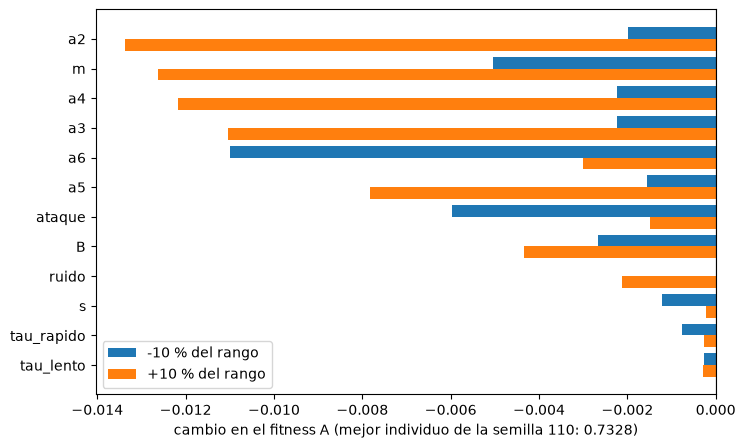

In [ ]:
mejor_semilla = tabla_meta["aptitud final"].idxmax()
mejor_ind = meta[meta["semilla"] == mejor_semilla].iloc[-1][["mejor_" + g[0] for g in GENES]].to_numpy(dtype=float)
base_fit = fitness(mejor_ind)
assert abs(base_fit - tabla_meta.loc[mejor_semilla, "aptitud final"]) < 1e-9

filas = []
for i, (nombre, *_) in enumerate(GENES):
    fila = [nombre]
    for delta in (-0.1, 0.1):
        x = mejor_ind.copy()
        x[i] = np.clip(x[i] + delta, 0, 1)
        fila.append(fitness(x) - base_fit)
    filas.append(fila)
tornado = pd.DataFrame(filas, columns=["gen", "-10 %", "+10 %"]).set_index("gen")
tornado["efecto"] = tornado[["-10 %", "+10 %"]].abs().max(axis=1)
tornado = tornado.sort_values("efecto")   # el de mayor efecto queda arriba al graficar

pos = np.arange(len(tornado))
plt.figure(figsize=(8, 5))
plt.barh(pos + 0.2, tornado["-10 %"], height=0.4, color="tab:blue", label="-10 % del rango")
plt.barh(pos - 0.2, tornado["+10 %"], height=0.4, color="tab:orange", label="+10 % del rango")
plt.yticks(pos, tornado.index)
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("cambio en el fitness A (mejor individuo de la semilla %d: %.4f)" % (mejor_semilla, base_fit))
plt.legend()
guardar_figura("tornado.png")
plt.show()

### Superficie de fitness: un gen a la vez

Se parte del mejor individuo y se recorre cada gen de 0 a 1 en 41 pasos, dejando los otros 11 quietos. Cada curva es
un corte de la superficie de fitness. Si las curvas son suaves, mover un gen un poco cambia el fitness un poco, y el
AG puede ir subiendo de a pasos; si tuvieran saltos o muchos picos, la búsqueda se perdería. La línea vertical marca
el valor que tiene el gen en el mejor individuo. Los valores se guardan en `resultados/superficie.csv`.

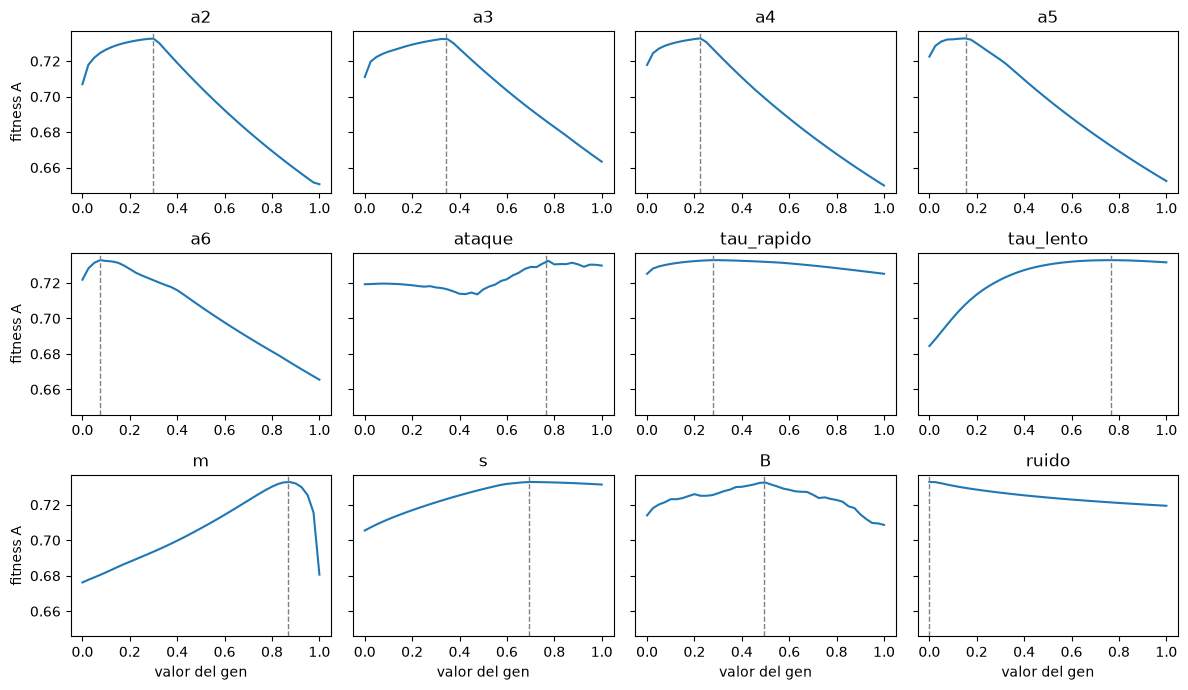

,fitness mínimo,fitness máximo,mayor salto entre vecinos,picos interiores
gen,,,,
a2,0.6506,0.7327,0.0110,1
a3,0.6633,0.7325,0.0087,1
a4,0.6499,0.7328,0.0066,1
a5,0.6524,0.7328,0.0061,1
a6,0.6655,0.7328,0.0063,1
ataque,0.7136,0.7325,0.0028,8
tau_rapido,0.7252,0.7328,0.0030,1
tau_lento,0.6845,0.7328,0.0041,1
m,0.6762,0.7328,0.0351,1


In [ ]:
ARCHIVO_SUPERFICIE = "resultados/superficie.csv"

if RECALCULAR or not os.path.exists(ARCHIVO_SUPERFICIE):
    filas = []
    for i, (nombre, *_) in enumerate(GENES):
        for valor in np.linspace(0, 1, 41):
            x = mejor_ind.copy()
            x[i] = valor
            filas.append((nombre, valor, fitness(x)))
    superficie = pd.DataFrame(filas, columns=["gen", "valor", "fitness"])
    superficie.to_csv(ARCHIVO_SUPERFICIE, index=False)
else:
    superficie = pd.read_csv(ARCHIVO_SUPERFICIE)

fig, ejes = plt.subplots(3, 4, figsize=(12, 7), sharey=True)
resumen_sup = []
for i, (eje, (nombre, *_)) in enumerate(zip(ejes.ravel(), GENES)):
    f = superficie[superficie["gen"] == nombre]["fitness"].to_numpy()
    eje.plot(np.linspace(0, 1, len(f)), f, color="tab:blue")
    eje.axvline(mejor_ind[i], color="gray", ls="--", lw=1)
    eje.set_title(nombre)
    maximos = int(np.sum((f[1:-1] > f[:-2]) & (f[1:-1] > f[2:])))   # picos interiores
    resumen_sup.append((nombre, f.min(), f.max(), np.abs(np.diff(f)).max(), maximos))
for eje in ejes[2]:
    eje.set_xlabel("valor del gen")
for eje in ejes[:, 0]:
    eje.set_ylabel("fitness A")
plt.tight_layout()
guardar_figura("superficie_genes.png")
plt.show()
pd.DataFrame(resumen_sup, columns=["gen", "fitness mínimo", "fitness máximo", "mayor salto entre vecinos",
                                   "picos interiores"]).set_index("gen").round(4)

### Prueba con una nota no vista (G4)

G4 no se usó para entrenar: las notas de entrenamiento siguen siendo D4, F4, A4, C5 y D5 (las de `REF_NOTAS`) y G4 solo
se carga aquí. Se mide el fitness A de cada nota por separado con el mejor individuo evolucionado y, de referencia,
con el Gen 0. Si el piano sintético aprendió el timbre, y no solo las 5 notas, G4 debería quedar parecida a las demás.

In [ ]:
assert 67 not in REF_NOTAS   # G4 (MIDI 67) no es una nota de entrenamiento

def fitness_nota(gen, midi, x_ref):
    db = stft_db(sintetizar_instrumento([midi], [2.0], gen))
    return 1 / (1 + np.mean(np.abs(db - stft_db(x_ref))) / 10)

notas_prueba = [(m, refs[m], "entrenamiento") for m in REF_NOTAS] + [(67, leer_wav("piano_G4.wav")[:2 * SR], "no vista")]
tabla_g4 = pd.DataFrame([(nombre_nota(m), uso, fitness_nota(mejor_ind, m, x), fitness_nota(gen0, m, x))
                         for m, x, uso in notas_prueba],
                        columns=["nota", "uso", "mejor evolucionado", "Gen 0"]).round(4)
entrenamiento = tabla_g4[tabla_g4["uso"] == "entrenamiento"]["mejor evolucionado"]
print("entrenamiento: %.4f ± %.4f (mín %.4f, máx %.4f) | G4: %.4f" %
      (entrenamiento.mean(), entrenamiento.std(), entrenamiento.min(), entrenamiento.max(),
       tabla_g4.iloc[-1]["mejor evolucionado"]))
tabla_g4

entrenamiento: 0.7379 ± 0.0680 (mín 0.6513, máx 0.8161) | G4: 0.7695


,nota,uso,mejor evolucionado,Gen 0
0,D4,entrenamiento,0.6513,0.6762
1,F4,entrenamiento,0.7284,0.6508
2,A4,entrenamiento,0.8161,0.7423
3,C5,entrenamiento,0.6986,0.6566
4,D5,entrenamiento,0.7949,0.7060
5,G4,no vista,0.7695,0.6977


### G4: individuos evolucionados contra individuos al azar

Para saber si el instrumento generaliza o solo sirve para las 5 notas de entrenamiento, se mide el fitness A en G4 de
los 10 individuos finales de la meta-evaluación y de 100 individuos al azar (semilla 2026). Si los evolucionados rinden
claramente más que los aleatorios en una nota que nunca vieron, hay generalización. Los valores se guardan en
`resultados/g4_azar.csv`.

In [ ]:
ARCHIVO_G4 = "resultados/g4_azar.csv"
x_g4 = notas_prueba[-1][1]   # la señal de G4 de la celda anterior

if RECALCULAR or not os.path.exists(ARCHIVO_G4):
    finales = meta.groupby("semilla").last()[["mejor_" + n for n, *_ in GENES]].to_numpy(dtype=float)
    aleatorios = np.random.default_rng(SEMILLA).random((100, N_GENES))
    g4 = pd.DataFrame([("AG", s, fitness_nota(ind, 67, x_g4)) for s, ind in zip(SEMILLAS_META, finales)] +
                      [("azar", i, fitness_nota(ind, 67, x_g4)) for i, ind in enumerate(aleatorios)],
                      columns=["grupo", "individuo", "fitness_g4"])
    g4.to_csv(ARCHIVO_G4, index=False)
else:
    g4 = pd.read_csv(ARCHIVO_G4)

ag_g4 = g4[g4["grupo"] == "AG"]["fitness_g4"]
azar_g4 = g4[g4["grupo"] == "azar"]["fitness_g4"]
u, p = mannwhitneyu(ag_g4, azar_g4, alternative="greater", method="exact")
print("Mann-Whitney exacto, una cola (AG > azar): U = %.0f, p = %.2g" % (u, p))
g4.groupby("grupo")["fitness_g4"].agg(["count", "mean", "std", "min", "max"]).round(4)

Mann-Whitney exacto, una cola (AG > azar): U = 1000, p = 2.1e-14


,count,mean,std,min,max
grupo,,,,,
AG,10,0.7878,0.0158,0.7562,0.8068
azar,100,0.5653,0.0425,0.4808,0.6977


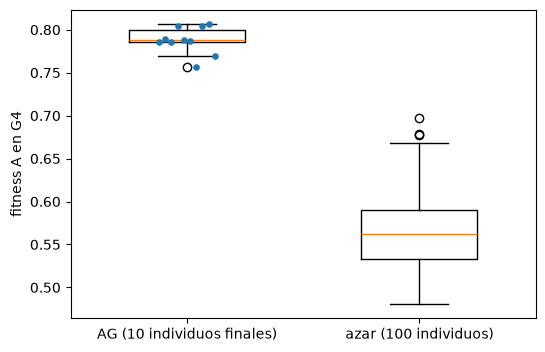

In [ ]:
plt.figure(figsize=(6, 4))
plt.boxplot([ag_g4, azar_g4], tick_labels=["AG (10 individuos finales)", "azar (100 individuos)"], widths=0.5)
plt.scatter(1 + np.linspace(-0.12, 0.12, len(ag_g4)), ag_g4, color="tab:blue", zorder=3, s=14)
plt.ylabel("fitness A en G4")
guardar_figura("g4_boxplot.png")
plt.show()

### Audios finales

Se guardan en `salidas/`: la nota A4 con el Gen 0 y con el mejor individuo evolucionado (para comparar con el piano
real de la sección 4) y la melodía completa del silbido tocada con el mejor individuo. `melodia_gen0.wav` y
`melodia_referencia.wav` ya se habían generado en la parte 1.

In [ ]:
nota_gen0 = guardar("nota_A4_gen0.wav", sintetizar_instrumento([69], [2.0], gen0))
nota_mejor = guardar("nota_A4_mejor.wav", sintetizar_instrumento([69], [2.0], mejor_ind))
mel_final = guardar("melodia_final.wav", sintetizar_instrumento(melodia, duraciones, mejor_ind))

for nombre, x in [("nota A4 con el Gen 0", nota_gen0), ("nota A4 con el mejor evolucionado", nota_mejor),
                  ("melodía completa con el mejor evolucionado", mel_final)]:
    print(nombre)
    display(Audio(x, rate=SR))

nota A4 con el Gen 0
nota A4 con el mejor evolucionado
melodía completa con el mejor evolucionado


## 9. Dos experimentos adicionales

Dos pruebas cortas para sostener mejor el análisis: provocar una convergencia prematura a propósito y cambiar un solo
operador a la vez. Como en las secciones anteriores, cada corrida se guarda en su CSV apenas termina y no se lanzan
solas (`CORRER_PREMATURA` y `CORRER_OPERADORES`).

### Convergencia prematura provocada

Para ver cómo se ve una convergencia prematura se arma a propósito una configuración que la favorece: población de solo
10 individuos, sin mutación (0.0) y torneo k = 5, que presiona mucho a elegir a los mejores. Es la base con esos tres
cambios (operadores de C1), con 5 semillas (2026 a 2030). Se compara con la base con las mismas semillas, que ya está
en `resultados/combinaciones.csv` (combinación C1). Las corridas nuevas se guardan en `resultados/prematura.csv`.

In [ ]:
# lo usan los procesos del cálculo en paralelo
SEMILLAS_PREMATURA = [SEMILLA + i for i in range(5)]
PREMATURA = {**BASE, "N": 10, "p_mut": 0.0, "k": 5}

def correr_prematura(semilla):
    historial, _, _ = evolucionar(np.random.default_rng(semilla), **OPERADORES, **PREMATURA)
    historial.insert(0, "semilla", semilla)
    return historial

In [ ]:
CORRER_PREMATURA = False   # True lanza (o retoma) las corridas que falten
ARCHIVO_PREMATURA = "resultados/prematura.csv"

hechas_prem = set(pd.read_csv(ARCHIVO_PREMATURA)["semilla"]) if os.path.exists(ARCHIVO_PREMATURA) else set()
faltan_prem = [s for s in SEMILLAS_PREMATURA if s not in hechas_prem]

if faltan_prem and CORRER_PREMATURA:
    inicio = time.time()
    for (semilla,), historial in en_paralelo([("correr_prematura", (s,)) for s in faltan_prem]):
        # cada corrida se guarda apenas termina
        historial.to_csv(ARCHIVO_PREMATURA, mode="a", header=not os.path.exists(ARCHIVO_PREMATURA), index=False)
        hechas_prem.add(semilla)
        print("semilla %d lista (%d de %d, %.0f min)" % (semilla, len(hechas_prem), len(SEMILLAS_PREMATURA), (time.time() - inicio) / 60))
else:
    print("corridas guardadas: %d de %d" % (len(hechas_prem), len(SEMILLAS_PREMATURA)))
    if faltan_prem:
        print("faltan %d; CORRER_PREMATURA = True las lanza" % len(faltan_prem))

corridas guardadas: 0 de 5
faltan 5; CORRER_PREMATURA = True las lanza


### Resultado de la convergencia prematura

Cada fila es el promedio de las 5 semillas. La última generación con mejora es la última en que la aptitud máxima subió
más de 0.0001 respecto a la anterior; la corrida termina 20 generaciones después. La diversidad final es la desviación
estándar media de los genes: 0 significa que todos los individuos son iguales.

In [ ]:
def resumen_corrida(d):
    final, inicio = d["maximo"].iloc[-1], d["maximo"].iloc[0]
    meta = inicio + 0.9 * (final - inicio)
    mejoras = d.loc[d["maximo"].diff() > 0.0001, "generacion"]
    return {"aptitud en Gen 0": inicio, "aptitud final": final,
            "evaluaciones hasta 90 % de la mejora": d.loc[d["maximo"] >= meta, "evaluaciones"].iloc[0],
            "última generación con mejora": mejoras.max() if len(mejoras) else 0,
            "generaciones": d["generacion"].iloc[-1], "evaluaciones": d["evaluaciones"].iloc[-1],
            "diversidad final": d["diversidad"].iloc[-1]}

prem = pd.read_csv(ARCHIVO_PREMATURA)
base_prem = pd.read_csv("resultados/combinaciones.csv").query("combinacion == 'C1'")   # la base con las mismas 5 semillas
grupos_prem = [("base (N = 60, mutación 0.08, k = 3)", base_prem), ("provocada (N = 10, mutación 0, k = 5)", prem)]
por_corrida_prem = {nombre: pd.DataFrame([resumen_corrida(d) for _, d in datos.groupby("semilla")]) for nombre, datos in grupos_prem}
for nombre, r in por_corrida_prem.items():
    print("%-40s aptitud final por semilla: %s" % (nombre, " ".join("%.4f" % v for v in r["aptitud final"])))
pd.DataFrame({nombre: r.mean() for nombre, r in por_corrida_prem.items()}).T.round(4)

base (N = 60, mutación 0.08, k = 3)      aptitud final por semilla: 0.7308 0.7322 0.7321 0.7322 0.7310
provocada (N = 10, mutación 0, k = 5)    aptitud final por semilla: 0.6511 0.6733 0.7120 0.6799 0.6910


,aptitud en Gen 0,aptitud final,evaluaciones hasta 90 % de la mejora,última generación con mejora,generaciones,evaluaciones,diversidad final
"base (N = 60, mutación 0.08, k = 3)",0.6881,0.7316,795.6,37.8,69.6,3890.2,0.026
"provocada (N = 10, mutación 0, k = 5)",0.6541,0.6815,20.0,4.4,24.8,46.0,0.000


### Operadores por separado

En la comparación de C1, C2 y C3 los tres operadores cambiaban a la vez. Aquí se parte de la base (torneo +
blend-alpha + gaussiana) y se cambia un solo operador: ruleta en vez de torneo, cruce uniforme en vez de blend-alpha o
mutación uniforme en vez de gaussiana, con 3 semillas (2026 a 2028) cada uno. La mutación no uniforme no se repite: C3
es justo la base con ese cambio, y sus semillas 2026 a 2028 ya están en `resultados/combinaciones.csv`; la base sale
de `resultados/configs.csv`. Las corridas nuevas se guardan en `resultados/operadores.csv`.

In [ ]:
# lo usan los procesos del cálculo en paralelo
VARIANTES_OPERADOR = {
    "ruleta": dict(seleccion="ruleta"),
    "cruce uniforme": dict(cruce="uniforme"),
    "mutación uniforme": dict(mutacion="uniforme"),
}
SEMILLAS_OPERADOR = [SEMILLA + i for i in range(3)]

def correr_operador(nombre, semilla):
    historial, _, _ = evolucionar(np.random.default_rng(semilla), **{**OPERADORES, **VARIANTES_OPERADOR[nombre]}, **BASE)
    historial.insert(0, "semilla", semilla)
    historial.insert(0, "operador", nombre)
    return historial

In [ ]:
CORRER_OPERADORES = False   # True lanza (o retoma) las corridas que falten
ARCHIVO_OPERADORES = "resultados/operadores.csv"

hechas_op = set()
if os.path.exists(ARCHIVO_OPERADORES):
    previas = pd.read_csv(ARCHIVO_OPERADORES)
    hechas_op = set(zip(previas["operador"], previas["semilla"]))
faltan_op = [(n, s) for n in VARIANTES_OPERADOR for s in SEMILLAS_OPERADOR if (n, s) not in hechas_op]

if faltan_op and CORRER_OPERADORES:
    inicio = time.time()
    for (nombre, semilla), historial in en_paralelo([("correr_operador", t) for t in faltan_op]):
        historial.to_csv(ARCHIVO_OPERADORES, mode="a", header=not os.path.exists(ARCHIVO_OPERADORES), index=False)
        hechas_op.add((nombre, semilla))
        print("%s, semilla %d lista (%d de %d, %.0f min)" %
              (nombre, semilla, len(hechas_op), len(VARIANTES_OPERADOR) * len(SEMILLAS_OPERADOR), (time.time() - inicio) / 60))
else:
    print("corridas guardadas: %d de %d" % (len(hechas_op), len(VARIANTES_OPERADOR) * len(SEMILLAS_OPERADOR)))
    if faltan_op:
        print("faltan %d; CORRER_OPERADORES = True las lanza" % len(faltan_op))

corridas guardadas: 0 de 9
faltan 9; CORRER_OPERADORES = True las lanza
